In [1]:
import pandas as pd

corpus = pd.read_csv("../data/corpus.csv")
corpus = corpus[corpus["remarque"].fillna("") != "exclure"]

X = corpus["titre"]
y = corpus["theme_final"]

print(len(corpus), "titres")
y.value_counts()

236 titres


theme_final
education    43
societe      42
sante        40
politique    39
economie     36
sport        36
Name: count, dtype: int64

Étape 2 : la baseline (TF-IDF sur les mots + régression logistique)

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

baseline = make_pipeline(
    TfidfVectorizer(lowercase=True),
    LogisticRegression(max_iter=1000)
)
baseline

Pipeline(steps=[('tfidfvectorizer', TfidfVectorizer()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, classification_report

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pred_base = cross_val_predict(baseline, X, y, cv=cv)

print("Macro-F1 baseline :", round(f1_score(y, pred_base, average="macro"), 3))
print(classification_report(y, pred_base))

Macro-F1 baseline : 0.593
              precision    recall  f1-score   support

    economie       0.50      0.31      0.38        36
   education       0.60      0.77      0.67        43
   politique       0.69      0.56      0.62        39
       sante       0.77      0.75      0.76        40
     societe       0.48      0.71      0.57        42
       sport       0.68      0.47      0.56        36

    accuracy                           0.61       236
   macro avg       0.62      0.60      0.59       236
weighted avg       0.62      0.61      0.60       236



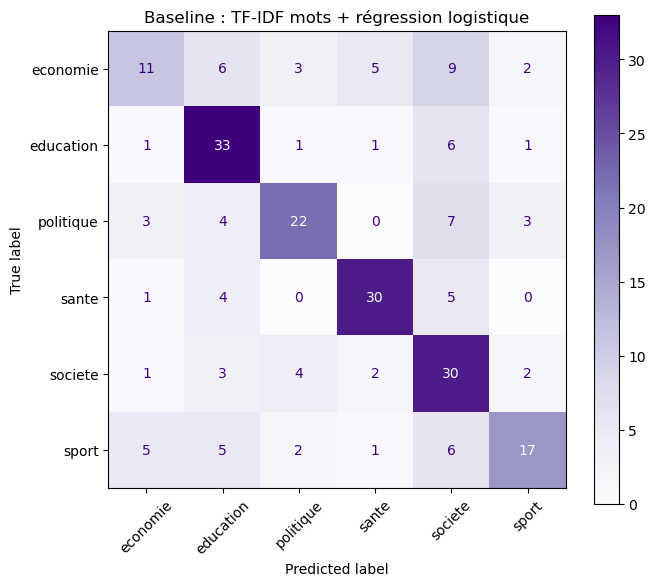

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y, pred_base, ax=ax, cmap="Purples", xticks_rotation=45)
ax.set_title("Baseline : TF-IDF mots + régression logistique")
plt.tight_layout()
plt.savefig("../resultats/matrice_confusion_baseline.png", dpi=150)
plt.show()